In [ ]:
!pip install -q torch transformers datasets safetensors huggingface_hub matplotlib

In [2]:
import copy
import gc
import glob
import math
import time
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from huggingface_hub import hf_hub_download, snapshot_download
from safetensors import safe_open
from safetensors.torch import load_file
from transformers import (
    AttentionInterface,
    AutoModelForCausalLM,
    AutoTokenizer,
    DynamicCache,
)
from transformers.models.qwen3.modeling_qwen3 import apply_rotary_pos_emb
from transformers.models.qwen3_5 import modeling_qwen3_5

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
MODEL_NAME = "Qwen/Qwen3-0.6B"
EAGLE_NAME = "GavinLucky/SGLang-EAGLE3-Qwen3-0.6B-SpecForge"
MTP_MODEL_NAME = "Qwen/Qwen3.5-0.8B"
DTYPE = torch.bfloat16
SEED = 0

torch.manual_seed(SEED)
transformers.logging.set_verbosity_error()
print(f"Using device: {DEVICE}")

Using device: mps


# LLM Model Serving

---
# 1) Introduction

A serving engine turns a model into an endpoint that answers many users at once. The model's
weights are fixed; what the engine controls is **memory, scheduling and the number of forward
passes per generated token**. It is judged by:

| Metric | Meaning | Dominated by |
|---|---|---|
| TTFT (time to first token) | Arrival to first output token | Queueing + **prefill** of the prompt |
| ITL / TPOT (inter-token latency) | Gap between output tokens | **Decode** step time |
| Throughput | Output tokens/s across all users | Batch size, which is bounded by KV cache memory |
| Goodput | Requests/s that meet TTFT and ITL targets | All of the above |

The KV cache is the central resource: every running request holds the keys and values of all its
tokens in every layer, and decode reads all of it at every step. vLLM, SGLang and TensorRT-LLM are
built around managing it. Their core mechanisms:

| Section | Mechanism | Engine that popularised it |
|---|---|---|
| 4.1–4.3 | Paged KV cache, varlen batching, continuous batching | vLLM (PagedAttention) |
| 4.4 | Prefix caching with a radix tree and LRU eviction | SGLang (RadixAttention) |
| 4.5 | Tiered KV storage: offload to host memory | LMCache, SGLang HiCache, vLLM KV connectors |
| 4.6 | Prefill/decode interference, chunked prefill, disaggregation | Sarathi-Serve, DistServe, Mooncake |
| 4.7 | KV cache quantization: FP8, INT8/INT4, KIVI | vLLM / SGLang `kv_cache_dtype` |
| 4.8 | Speculative decoding with an EAGLE-3 draft head | EAGLE-3, SpecForge |
| 4.9 | Self-speculation with a native MTP head | DeepSeek-V3, Qwen3-Next / Qwen3.5 |

The transformer itself is imported from `transformers`; everything around it is built here.

---
# 2) Setup

`Qwen3-0.6B` (28 layers, 8 KV heads × 128 dims, GQA) runs in bf16, about 1.2 GB of weights. Requests come from real
multi-turn conversations in UltraChat.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE).to(DEVICE).eval()
config = model.config
NUM_LAYERS, NUM_KV_HEADS, HEAD_DIM = (
    config.num_hidden_layers,
    config.num_key_value_heads,
    config.head_dim,
)
EOS_IDS = {tokenizer.convert_tokens_to_ids("<|im_end|>"), tokenizer.eos_token_id}


def sync() -> None:
    """Wait for queued device work so wall-clock timings are real."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


def device_gib() -> float:
    """Device memory allocated by PyTorch."""
    if DEVICE.type == "cuda":
        return torch.cuda.memory_allocated() / 2**30
    if DEVICE.type == "mps":
        return torch.mps.current_allocated_memory() / 2**30
    return 0.0


print(
    f"{MODEL_NAME}: {sum(p.numel() for p in model.parameters()) / 1e9:.2f}B params, "
    f"{device_gib():.2f} GiB on {DEVICE}"
)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Qwen/Qwen3-0.6B: 0.60B params, 1.11 GiB on mps


The production engines expose everything below as flags. This cell runs only where vLLM is
installed on a CUDA GPU; it is the reference for what the cells below open up.

In [4]:
try:
    import vllm

    assert DEVICE.type == "cuda"
    llm = vllm.LLM(
        MODEL_NAME,
        enable_prefix_caching=True,
        kv_cache_dtype="fp8",
        max_num_batched_tokens=2048,
        speculative_config={
            "method": "eagle3",
            "model": EAGLE_NAME,
            "num_speculative_tokens": 3,
        },
    )
    print(llm.generate(["The capital of France is"])[0].outputs[0].text)
except (ImportError, AssertionError):
    print(
        "vLLM needs a CUDA GPU; equivalent SGLang server:\n"
        f"  python -m sglang.launch_server --model {MODEL_NAME} --kv-cache-dtype fp8_e4m3 "
        f"--speculative-algorithm EAGLE3 --speculative-draft-model-path {EAGLE_NAME} "
        "--chunked-prefill-size 2048"
    )

vLLM needs a CUDA GPU; equivalent SGLang server:
  python -m sglang.launch_server --model Qwen/Qwen3-0.6B --kv-cache-dtype fp8_e4m3 --speculative-algorithm EAGLE3 --speculative-draft-model-path GavinLucky/SGLang-EAGLE3-Qwen3-0.6B-SpecForge --chunked-prefill-size 2048


In [5]:
ultrachat = load_dataset("HuggingFaceH4/ultrachat_200k", split="test_sft")
conversations = [c["messages"] for c in ultrachat if len(c["messages"]) >= 6][:24]
print(f"{len(conversations)} conversations with >= 3 user turns; first user turn:")
print(conversations[0][0]["content"][:200])

24 conversations with >= 3 user turns; first user turn:
How does the author propose to fix the problem of science alienation in our educational system? What changes does she suggest should be made to science education? Answer according to: Science educatio


---
# 3) The math

**KV cache size.** Per token, a model with $L$ layers, $n_{kv}$ KV heads of width $d_h$ and $b$
bytes per value stores

$$
\text{bytes/token} = 2 \cdot L \cdot n_{kv} \cdot d_h \cdot b .
$$

For Qwen3-0.6B in bf16 that is $2 \cdot 28 \cdot 8 \cdot 128 \cdot 2 = 112$ KiB, as much as
models several times its size, because KV width depends on heads, not parameters. With $M$ bytes left for
the cache after weights and activations, the engine can hold $M / \text{bytes/token}$ tokens across
**all** running requests; that number, not compute, caps the batch size.

**Fragmentation.** Reserving a contiguous `max_len` slab per request wastes
$\text{max\_len} - (\text{prompt} + \text{output})$ tokens per request. Paging stores the cache in
fixed blocks of $B$ tokens and wastes at most $B - 1$ tokens per request.

**Prefill vs decode.** A forward over $T$ new tokens with $P$ parameters costs about $2PT$ FLOPs
and must read the $2P$ bytes of bf16 weights once, so its arithmetic intensity is about $T$
FLOPs/byte. Prefill ($T$ = prompt length, hundreds to thousands) is **compute-bound**; decode
($T$ = batch size, one token per request) is **memory-bound** until the batch reaches the
hardware's FLOP/byte ratio (≈300 on an H100). Batching decodes is nearly free; mixing a long
prefill into a decode step stalls every decode in the batch.

**Speculative decoding.** If a draft proposes $k$ tokens and each is accepted with probability
$\alpha$ (independently, for intuition), one target forward yields

$$
\mathbb{E}[\text{tokens per target step}] = \frac{1 - \alpha^{k+1}}{1 - \alpha},
$$

and with greedy verification the output is **identical** to the target's own greedy output. The
speedup is that number divided by the relative cost of a draft-and-verify step.

---
# 4) From-scratch implementation

## 4.1 Block pool and block tables

The cache for every layer is one tensor of shape
`(num_blocks, block_size, num_kv_heads, head_dim)`. A request owns a **block table**, the list of
block ids holding its tokens in order; token $p$ lives in block `table[p // B]` at offset `p % B`.
Blocks are reference-counted so that requests (and later the prefix cache) can share them.

In [6]:
BLOCK_SIZE = 16


class BlockPool:
    """Fixed pool of KV blocks for all layers, with reference counts."""

    def __init__(self, num_blocks: int) -> None:
        shape = (NUM_LAYERS, num_blocks, BLOCK_SIZE, NUM_KV_HEADS, HEAD_DIM)
        self.k = torch.zeros(shape, dtype=DTYPE, device=DEVICE)
        self.v = torch.zeros(shape, dtype=DTYPE, device=DEVICE)
        self.free = list(range(num_blocks))[::-1]
        self.ref = [0] * num_blocks

    def allocate(self) -> int:
        block = self.free.pop()
        self.ref[block] = 1
        return block

    def share(self, block: int) -> None:
        self.ref[block] += 1

    def release(self, block: int) -> None:
        self.ref[block] -= 1
        if self.ref[block] == 0:
            self.free.append(block)


KV_BYTES_PER_TOKEN = (
    2 * NUM_LAYERS * NUM_KV_HEADS * HEAD_DIM * torch.finfo(DTYPE).bits // 8
)
KV_BUDGET_GIB = 1.0
NUM_BLOCKS = int(KV_BUDGET_GIB * 2**30 / (KV_BYTES_PER_TOKEN * BLOCK_SIZE))
pool = BlockPool(NUM_BLOCKS)
print(
    f"KV bytes/token: {KV_BYTES_PER_TOKEN / 1024:.0f} KiB; {KV_BUDGET_GIB} GiB -> "
    f"{NUM_BLOCKS} blocks = {NUM_BLOCKS * BLOCK_SIZE:,} tokens"
)

KV bytes/token: 112 KiB; 1.0 GiB -> 585 blocks = 9,360 tokens


## 4.2 Paged attention as a `transformers` attention backend

`transformers` lets a model use any registered attention function. The one below receives the
batch's queries, keys and values after RoPE, **writes** the new keys and values into the pool at
their slots, **gathers** each request's blocks, and attends. Requests are packed into one
flattened token stream of shape `(1, total_tokens)` with explicit position ids, the "varlen"
layout production kernels use: no padding, and prefill chunks and decode tokens of different
requests share one forward.

In [7]:
@dataclass
class PagedBatch:
    """Per-forward metadata: where new tokens go and which blocks each request reads."""

    # (total_tokens,) flat slot index block * BLOCK_SIZE + offset of every new token
    slots: torch.Tensor
    # per request: (start in packed batch, num new tokens, context length, block table)
    segments: list


def paged_attention(
    module, query, key, value, attention_mask, scaling=None, dropout=0.0, **kwargs
):
    """query (1, num_heads, total_tokens, head_dim); key/value (1, num_kv_heads, total_tokens, head_dim)."""
    meta: PagedBatch = kwargs["paged"]
    layer = module.layer_idx
    k_pool = pool.k[layer].view(-1, NUM_KV_HEADS, HEAD_DIM)
    v_pool = pool.v[layer].view(-1, NUM_KV_HEADS, HEAD_DIM)
    # (1, num_kv_heads, total_tokens, head_dim) -> (total_tokens, num_kv_heads, head_dim)
    k_pool[meta.slots] = key[0].transpose(0, 1)
    v_pool[meta.slots] = value[0].transpose(0, 1)
    outputs = []
    for start, num_new, ctx_len, table in meta.segments:
        # (num_blocks_req, BLOCK_SIZE, kv, d) -> (1, kv, ctx_len, d)
        k = (
            pool.k[layer][table]
            .reshape(-1, NUM_KV_HEADS, HEAD_DIM)[:ctx_len]
            .transpose(0, 1)[None]
        )
        v = (
            pool.v[layer][table]
            .reshape(-1, NUM_KV_HEADS, HEAD_DIM)[:ctx_len]
            .transpose(0, 1)[None]
        )
        q = query[:, :, start : start + num_new]
        # new token i sits at absolute position ctx_len - num_new + i
        q_pos = torch.arange(ctx_len - num_new, ctx_len, device=q.device)[:, None]
        mask = torch.arange(ctx_len, device=q.device)[None] <= q_pos
        outputs.append(
            F.scaled_dot_product_attention(
                q, k, v, attn_mask=mask, scale=scaling, enable_gqa=True
            )
        )
    # (1, num_heads, total_tokens, head_dim) -> (1, total_tokens, num_heads, head_dim)
    return torch.cat(outputs, dim=2).transpose(1, 2).contiguous(), None


AttentionInterface.register("paged", paged_attention)

`Request` holds a request's tokens and block table; `forward_step` runs one packed forward over
any mix of prefill chunks and decode tokens and returns the logits at the last new position of
each request.

In [8]:
@dataclass
class Request:
    prompt: list[int]
    max_new: int
    tokens: list[int] = field(default_factory=list)
    blocks: list[int] = field(default_factory=list)
    num_computed: int = 0
    arrival: float = 0.0
    token_times: list[float] = field(default_factory=list)

    def __post_init__(self) -> None:
        self.tokens = list(self.prompt)

    @property
    def done(self) -> bool:
        out = self.tokens[len(self.prompt) :]
        return len(out) >= self.max_new or (out and out[-1] in EOS_IDS)


@torch.no_grad()
def forward_step(requests: list[Request], chunks: list[int]) -> torch.Tensor:
    """Compute the next chunks[i] uncomputed tokens of each request; returns (num_requests, vocab_size)."""
    input_ids, positions, slots, segments, start = [], [], [], [], 0
    for req, n in zip(requests, chunks):
        end = req.num_computed + n
        while len(req.blocks) * BLOCK_SIZE < end:
            req.blocks.append(pool.allocate())
        new_positions = list(range(req.num_computed, end))
        input_ids += req.tokens[req.num_computed : end]
        positions += new_positions
        slots += [
            req.blocks[p // BLOCK_SIZE] * BLOCK_SIZE + p % BLOCK_SIZE
            for p in new_positions
        ]
        segments.append((start, n, end, torch.tensor(req.blocks, device=DEVICE)))
        start += n
        req.num_computed = end
    # only the last new position of each request needs logits
    last = torch.tensor([s + n - 1 for s, n, _, _ in segments], device=DEVICE)
    out = model(
        input_ids=torch.tensor([input_ids], device=DEVICE),
        position_ids=torch.tensor([positions], device=DEVICE),
        attention_mask={"full_attention": None},
        use_cache=False,
        logits_to_keep=last,
        paged=PagedBatch(torch.tensor(slots, device=DEVICE), segments),
    )
    return out.logits[0]


def chat_ids(messages: list[dict]) -> list[int]:
    """Chat-templated prompt token ids (non-thinking mode)."""
    text = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    return tokenizer(text).input_ids

The check: three requests of different lengths are prefilled together in one packed forward and
then decoded together; the result must equal Hugging Face's dense-cache greedy generation of each
request on its own.

In [9]:
prompts = [chat_ids([conversations[i][0]]) for i in range(3)]
model.set_attn_implementation("sdpa")
reference = [
    model.generate(
        torch.tensor([p], device=DEVICE), max_new_tokens=32, do_sample=False
    )[0, len(p) :].tolist()
    for p in prompts
]
model.set_attn_implementation("paged")

batch = [Request(p, 32) for p in prompts]
logits = forward_step(batch, [len(p) for p in prompts])
for _ in range(32):
    for req, row in zip(batch, logits):
        req.tokens.append(int(row.argmax()))
    logits = forward_step(batch, [1, 1, 1])
for req, ref in zip(batch, reference):
    out = req.tokens[len(req.prompt) : len(req.prompt) + 32]
    print(
        f"prompt {len(req.prompt):>4} tokens: {sum(a == b for a, b in zip(out, ref))}/32 tokens match "
        f"| {tokenizer.decode(out[:12])!r}"
    )
    for b in req.blocks:
        pool.release(b)

prompt 1204 tokens: 32/32 tokens match | 'The author proposes to address the problem of science alienation in'
prompt  483 tokens: 32/32 tokens match | 'The tolerant rice cultivar **Koshihikari**'
prompt  105 tokens: 32/32 tokens match | '**The Unseen Flame**\n\nThe storm raged, a'


## 4.3 Continuous batching on a paged cache

`serve` is the scheduler loop. Each iteration it admits waiting requests while blocks are
available (reserving all of a request's blocks at admission), gives every running request either a prefill chunk or one decode token (subject to a
per-step token budget), runs one `forward_step`, samples greedily, and frees the blocks of
finished requests immediately. `on_admit`, `on_finish` and `evict` are hooks the prefix cache uses later.

In [10]:
def serve(
    requests: list[Request],
    max_running: int = 16,
    token_budget: int = 4096,
    on_admit=None,
    on_finish=None,
    evict=None,
) -> dict:
    """Run all requests to completion; returns timing statistics."""
    waiting, running, finished = list(requests), [], []
    prefill_tokens, start = 0, time.time()
    for req in waiting:
        req.arrival = start
    while waiting or running:
        while waiting and len(running) < max_running:
            need = math.ceil((len(waiting[0].prompt) + waiting[0].max_new) / BLOCK_SIZE)
            if len(pool.free) < need and evict:
                evict(need - len(pool.free))
            if len(pool.free) < need:
                break
            req = waiting.pop(0)
            if on_admit:
                on_admit(req)
            # reserve every block the request can need, so admitted requests never run dry
            while len(req.blocks) * BLOCK_SIZE < len(req.prompt) + req.max_new:
                req.blocks.append(pool.allocate())
            running.append(req)
        budget, chunks = token_budget, []
        for req in running:
            remaining = len(req.tokens) - req.num_computed
            n = 1 if remaining == 1 else max(1, min(remaining, budget))
            chunks.append(n)
            budget -= n
        prefill_tokens += sum(
            n for req, n in zip(running, chunks) if req.num_computed < len(req.prompt)
        )
        logits = forward_step(running, chunks)
        sync()
        now = time.time()
        for req, row in zip(running, logits):
            if req.num_computed == len(req.tokens):
                req.tokens.append(int(row.argmax()))
                req.token_times.append(now)
        for req in [r for r in running if r.done]:
            running.remove(req)
            finished.append(req)
            if on_finish:
                on_finish(req)
            for b in req.blocks:
                pool.release(b)
            req.blocks = []
    elapsed = time.time() - start
    output_tokens = sum(len(r.token_times) for r in finished)
    return {
        "elapsed": elapsed,
        "throughput": output_tokens / elapsed,
        "ttft": sum(r.token_times[0] - r.arrival for r in finished) / len(finished),
        "prefill_tokens": prefill_tokens,
    }

Throughput as a function of how many requests may run at once, on 16 first-turn UltraChat
prompts with 32 output tokens each:

In [11]:
first_turns = [chat_ids([c[0]]) for c in conversations] + [
    chat_ids([c[2]]) for c in conversations[:8]
]
for max_running in [1, 4, 16]:
    stats = serve([Request(p, 32) for p in first_turns[:16]], max_running=max_running)
    print(
        f"max_running {max_running:>2}: {stats['throughput']:6.1f} output tok/s, "
        f"mean TTFT {stats['ttft']:5.1f}s, total {stats['elapsed']:.0f}s"
    )

max_running  1:   31.3 output tok/s, mean TTFT   9.1s, total 16s


max_running  4:   62.8 output tok/s, mean TTFT   4.4s, total 8s


max_running 16:   84.8 output tok/s, mean TTFT   1.9s, total 6s


Batching more requests per step raises throughput several-fold. On a GPU with fused paged-attention
kernels a decode step is memory-bound, so 16 requests cost little more than one; this eager
implementation launches one attention call per request, so the per-step cost still grows with
the batch (measured below), and the gain is smaller than in a production engine. Mean TTFT rises with concurrency here because all
16 requests arrive at once and prefills share steps with decodes.

Paging is what makes that concurrency affordable. Using the **real** prompt lengths and
reference-answer lengths of the UltraChat requests:

In [12]:
lengths = [
    len(chat_ids([c[0]])) + len(tokenizer(c[1]["content"]).input_ids)
    for c in conversations
]
MAX_LEN = 4096
contiguous_waste = sum(MAX_LEN - n for n in lengths) / (MAX_LEN * len(lengths))
paged_waste = sum(math.ceil(n / BLOCK_SIZE) * BLOCK_SIZE - n for n in lengths) / sum(
    math.ceil(n / BLOCK_SIZE) * BLOCK_SIZE for n in lengths
)
tokens_in_budget = NUM_BLOCKS * BLOCK_SIZE
mean_len = sum(lengths) / len(lengths)
print(f"Mean request length {mean_len:.0f} tokens (prompt + reference answer)")
print(
    f"Contiguous max_len={MAX_LEN} slabs: {contiguous_waste:.0%} of reserved KV unused, "
    f"{tokens_in_budget // MAX_LEN} concurrent requests in {KV_BUDGET_GIB} GiB"
)
print(
    f"Paged, block {BLOCK_SIZE}: {paged_waste:.1%} unused, "
    f"~{int(tokens_in_budget / (mean_len * (1 + paged_waste)))} concurrent requests"
)

Mean request length 559 tokens (prompt + reference answer)
Contiguous max_len=4096 slabs: 86% of reserved KV unused, 2 concurrent requests in 1.0 GiB
Paged, block 16: 1.3% unused, ~16 concurrent requests


## 4.4 Prefix caching with a radix tree

Multi-turn chat, agents and few-shot prompts resend the same prefix over and over. SGLang's
**RadixAttention** keeps the KV blocks of finished requests in a radix tree keyed by token ids;
a new request walks the tree, reuses every matching block, and only prefills the rest. Leaves
that no running request uses are evicted least-recently-used when the pool runs short.

The tree here is block-granular (edges are sequences of full 16-token blocks). vLLM's version
uses the same granularity with a hash chain instead of a tree: block $i$ is keyed by
$\text{hash}(\text{key}_{i-1}, \text{tokens}_i)$.

In [13]:
class RadixNode:
    """An edge of full blocks: keys are token tuples, values are pool block ids."""

    def __init__(self, keys: list[tuple], blocks: list[int], parent=None) -> None:
        self.keys, self.blocks, self.parent = keys, blocks, parent
        self.children: dict[tuple, "RadixNode"] = {}
        self.last_used = time.time()


class RadixCache:
    """Block-granular radix tree over token prefixes with LRU leaf eviction."""

    def __init__(self) -> None:
        self.root = RadixNode([], [])
        self.hits = self.lookups = 0

    @staticmethod
    def split_blocks(tokens: list[int]) -> list[tuple]:
        n = len(tokens) // BLOCK_SIZE
        return [tuple(tokens[i * BLOCK_SIZE : (i + 1) * BLOCK_SIZE]) for i in range(n)]

    def _split(self, node: RadixNode, at: int) -> RadixNode:
        """Split node so its first `at` blocks become a new parent."""
        head = RadixNode(node.keys[:at], node.blocks[:at], node.parent)
        node.parent.children[head.keys[0]] = head
        node.keys, node.blocks, node.parent = node.keys[at:], node.blocks[at:], head
        head.children[node.keys[0]] = node
        return head

    def match(self, tokens: list[int]) -> list[int]:
        """Block ids of the longest cached prefix of tokens."""
        keys, node, blocks = self.split_blocks(tokens), self.root, []
        while keys and keys[0] in node.children:
            child = node.children[keys[0]]
            n = 0
            while n < len(child.keys) and n < len(keys) and child.keys[n] == keys[n]:
                n += 1
            if n < len(child.keys):
                child = self._split(child, n)
            child.last_used = time.time()
            blocks += child.blocks
            keys, node = keys[n:], child
        return blocks

    def insert(self, tokens: list[int], blocks: list[int]) -> None:
        """Add a finished request's full blocks; the tree takes a reference to new ones."""
        keys, node, i = self.split_blocks(tokens), self.root, 0
        while i < len(keys) and keys[i] in node.children:
            child = node.children[keys[i]]
            n = 0
            while (
                n < len(child.keys)
                and i + n < len(keys)
                and child.keys[n] == keys[i + n]
            ):
                n += 1
            if n < len(child.keys):
                child = self._split(child, n)
            child.last_used = time.time()
            node, i = child, i + n
        if i < len(keys):
            for b in blocks[i : len(keys)]:
                pool.share(b)
            new = RadixNode(keys[i:], blocks[i : len(keys)], node)
            node.children[keys[i]] = new

    def leaves(self) -> list[RadixNode]:
        out, stack = [], [self.root]
        while stack:
            n = stack.pop()
            stack += list(n.children.values())
            if not n.children and n is not self.root:
                out.append(n)
        return out

    def evict(self, num_blocks: int) -> int:
        """Free at least num_blocks from LRU leaves nobody else references."""
        freed = 0
        while freed < num_blocks:
            candidates = [
                l for l in self.leaves() if all(pool.ref[b] == 1 for b in l.blocks)
            ]
            if not candidates:
                break
            leaf = min(candidates, key=lambda l: l.last_used)
            for b in leaf.blocks:
                pool.release(b)
            freed += len(leaf.blocks)
            del leaf.parent.children[leaf.keys[0]]
        return freed

In [14]:
radix = RadixCache()


def admit_with_prefix(req: Request) -> None:
    """Reuse cached blocks; at least one prompt token is always recomputed for its logits."""
    radix.lookups += 1
    blocks = radix.match(req.prompt[:-1])
    for b in blocks:
        pool.share(b)
    req.blocks, req.num_computed = list(blocks), len(blocks) * BLOCK_SIZE
    radix.hits += bool(blocks)


def finish_into_cache(req: Request) -> None:
    """Hand the request's computed blocks to the tree (the last sampled token has no KV yet)."""
    radix.insert(req.tokens[: req.num_computed], req.blocks)


demo = Request(list(range(1000, 1040)), 1)
forward_step([demo], [40])
radix.insert(demo.tokens, demo.blocks)
print(f"Cached 40 tokens = {len(radix.split_blocks(demo.tokens))} full blocks")
print(
    f"Match of a request sharing 35 tokens: {len(radix.match(list(range(1000, 1035)) + [7] * 20))} blocks"
)
print(f"Match of an unrelated request: {len(radix.match([5] * 40))} blocks")
for b in demo.blocks:
    pool.release(b)
radix.evict(10**9)
print(f"Free blocks after evicting everything: {len(pool.free)}/{NUM_BLOCKS}")

Cached 40 tokens = 2 full blocks
Match of a request sharing 35 tokens: 2 blocks
Match of an unrelated request: 0 blocks
Free blocks after evicting everything: 585/585


The workload: 8 real UltraChat conversations behind one shared system prompt, served turn by turn
(all first turns, then all second turns, ...). Turn $t$ of a conversation resends the system
prompt and the full history, using the dataset's own assistant replies as history.

In [15]:
SYSTEM = (
    "You are a helpful, knowledgeable assistant. Answer accurately and concisely, cite "
    "uncertainty when you are not sure, prefer concrete examples, and format lists and code "
    "with Markdown. If a request is ambiguous, state your assumption and proceed. "
) * 6


def multi_turn_requests(
    num_conversations: int = 8, turns: int = 3, max_new: int = 16
) -> list[Request]:
    """Requests in arrival order: turn 1 of every conversation, then turn 2, ..."""
    out = []
    for t in range(turns):
        for c in conversations[:num_conversations]:
            history = [{"role": "system", "content": SYSTEM}] + c[: 2 * t + 1]
            out.append(Request(chat_ids(history), max_new))
    return out


reqs = multi_turn_requests()
print(
    f"{len(reqs)} requests, mean prompt {sum(len(r.prompt) for r in reqs) / len(reqs):.0f} tokens, "
    f"system prompt {len(tokenizer(SYSTEM).input_ids)} tokens"
)
no_cache = serve(reqs, max_running=8)
radix = RadixCache()
with_cache = serve(
    multi_turn_requests(),
    max_running=8,
    on_admit=admit_with_prefix,
    on_finish=finish_into_cache,
    evict=radix.evict,
)
for name, s in [("no prefix cache", no_cache), ("radix prefix cache", with_cache)]:
    print(
        f"{name:<20} prefill tokens {s['prefill_tokens']:>6}, mean TTFT {s['ttft']:5.2f}s, total {s['elapsed']:.0f}s"
    )
print(f"Cache hit rate: {radix.hits}/{radix.lookups} requests")
# return the cached blocks to the pool for the next experiments
radix.evict(10**9)
print(f"Free blocks: {len(pool.free)}/{NUM_BLOCKS}")

24 requests, mean prompt 904 tokens, system prompt 283 tokens


no prefix cache      prefill tokens  21694, mean TTFT 10.73s, total 26s
radix prefix cache   prefill tokens  10206, mean TTFT  7.42s, total 17s
Cache hit rate: 16/24 requests
Free blocks: 585/585


## 4.5 Offloading KV blocks to host memory

When the pool is full, eviction throws away KV that may be needed again (the user comes back to a
long conversation). A **second tier** keeps evicted blocks in host memory; a later hit copies
them back instead of recomputing. The trade-off is the copy bandwidth (PCIe, ~25–60 GB/s on
discrete GPUs; a memcpy on unified-memory machines like this one) against the prefill compute the
copy avoids.

In [16]:
@torch.no_grad()
def offload_and_restore_cost(num_tokens: int) -> dict:
    """Time to move num_tokens of KV device->host->device vs recompute them."""
    req = Request(first_turns[0] * (num_tokens // len(first_turns[0]) + 1), 1)
    req.tokens = req.prompt = req.prompt[:num_tokens]
    sync()
    start = time.time()
    forward_step([req], [num_tokens])
    sync()
    prefill_s = time.time() - start
    table = torch.tensor(req.blocks, device=DEVICE)
    start = time.time()
    host_k, host_v = pool.k[:, table].to("cpu"), pool.v[:, table].to("cpu")
    sync()
    offload_s = time.time() - start
    start = time.time()
    pool.k[:, table], pool.v[:, table] = host_k.to(DEVICE), host_v.to(DEVICE)
    sync()
    restore_s = time.time() - start
    for b in req.blocks:
        pool.release(b)
    return {
        "prefill": prefill_s,
        "offload": offload_s,
        "restore": restore_s,
        "bytes": host_k.numel() * host_k.element_size() * 2,
    }


for n in [512, 2048]:
    c = offload_and_restore_cost(n)
    print(
        f"{n:>5} tokens ({c['bytes'] / 2**20:5.0f} MiB): recompute {c['prefill'] * 1000:6.0f} ms | "
        f"restore from host {c['restore'] * 1000:5.0f} ms | offload {c['offload'] * 1000:5.0f} ms"
    )

  512 tokens (   56 MiB): recompute    238 ms | restore from host    14 ms | offload    21 ms


 2048 tokens (  224 MiB): recompute   1511 ms | restore from host    65 ms | offload    66 ms


Restoring is cheaper than recomputing, and the gap grows with length because prefill attention is
quadratic. Production systems extend the tiers further (local SSD, a shared pool across machines,
Mooncake's KV store) and key them by the same prefix hashes.

## 4.6 Prefill, decode, and disaggregation

First the two phases in isolation: prefill time vs prompt length, and decode step time vs batch
size.

In [17]:
@torch.no_grad()
def time_prefill(num_tokens: int) -> float:
    req = Request((first_turns[1] * 20)[:num_tokens], 1)
    sync()
    start = time.time()
    forward_step([req], [num_tokens])
    sync()
    for b in req.blocks:
        pool.release(b)
    return time.time() - start


@torch.no_grad()
def time_decode(batch_num: int, ctx: int = 512) -> float:
    reqs = [Request((first_turns[2] * 10)[:ctx], 1) for _ in range(batch_num)]
    forward_step(reqs, [ctx] * batch_num)
    for r in reqs:
        r.tokens.append(1)
    sync()
    start = time.time()
    forward_step(reqs, [1] * batch_num)
    sync()
    for r in reqs:
        for b in r.blocks:
            pool.release(b)
    return time.time() - start


for n in [128, 512, 2048]:
    t = time_prefill(n)
    print(f"prefill {n:>5} tokens: {t * 1000:6.0f} ms ({n / t:7.0f} tok/s)")
for b in [1, 4, 16]:
    t = time_decode(b)
    print(f"decode batch {b:>3}: {t * 1000:6.0f} ms per step ({b / t:7.0f} tok/s)")

prefill   128 tokens:     80 ms (   1598 tok/s)


prefill   512 tokens:    219 ms (   2335 tok/s)


prefill  2048 tokens:   1402 ms (   1461 tok/s)


decode batch   1:     32 ms per step (     31 tok/s)


decode batch   4:     72 ms per step (     55 tok/s)


decode batch  16:    225 ms per step (     71 tok/s)


Now the interference. Eight requests are decoding; at step 10 a 2,048-token prompt arrives.

- **Colocated, whole prefill**: the next step processes 2,048 + 8 tokens; every decoding request
  waits for it.
- **Chunked prefill** (Sarathi-Serve): the prompt is split into 256-token chunks, one per step,
  each mixed with the eight decode tokens. The spike shrinks to a chunk's cost, spread over more
  steps; TTFT of the new request grows a little.
- **Disaggregated** (DistServe, Mooncake): prefill runs on a separate GPU pool and ships the KV to
  the decode pool. Decode steps never contain prefill work; the price is the KV transfer and a
  second set of GPUs.

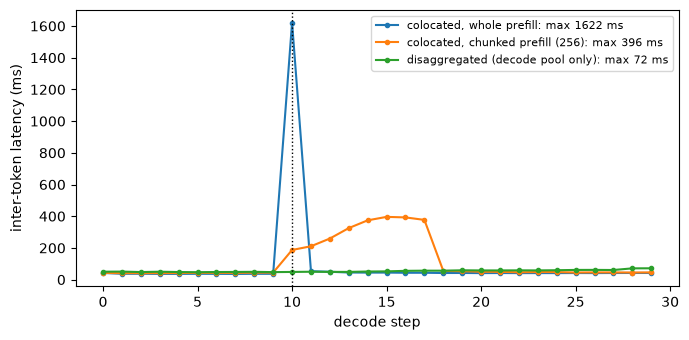

Disaggregation ships 224 MiB of KV for a 2,048-token prompt: 4.7 ms at 50 GB/s (RDMA / NVLink-class), 78 ms at 3 GB/s


In [18]:
@torch.no_grad()
def interference(chunk: int | None, steps: int = 30, arrive: int = 10) -> list[float]:
    """Inter-token latency (ms) of 8 decoding requests while a long prompt is admitted."""
    decoders = [Request(first_turns[i + 3], steps + 1) for i in range(8)]
    forward_step(decoders, [len(r.prompt) for r in decoders])
    for r in decoders:
        r.tokens.append(1)
    newcomer = Request((first_turns[1] * 20)[:2048], 1)
    itl = []
    for step in range(steps):
        batch, chunks = list(decoders), [1] * 8
        remaining = len(newcomer.tokens) - newcomer.num_computed
        if step >= arrive and remaining > 0 and chunk != 0:
            batch.append(newcomer)
            chunks.append(remaining if chunk is None else min(chunk, remaining))
        sync()
        start = time.time()
        forward_step(batch, chunks)
        sync()
        itl.append((time.time() - start) * 1000)
        for r in decoders:
            r.tokens.append(1)
    for r in decoders + [newcomer]:
        for b in r.blocks:
            pool.release(b)
    return itl


traces = {
    "colocated, whole prefill": interference(None),
    "colocated, chunked prefill (256)": interference(256),
    "disaggregated (decode pool only)": interference(0),
}
plt.figure(figsize=(7, 3.5))
for name, itl in traces.items():
    plt.plot(itl, marker=".", label=f"{name}: max {max(itl):.0f} ms")
plt.axvline(10, color="k", ls=":", lw=1)
plt.xlabel("decode step")
plt.ylabel("inter-token latency (ms)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

kv_bytes = 2048 * KV_BYTES_PER_TOKEN
print(
    f"Disaggregation ships {kv_bytes / 2**20:.0f} MiB of KV for a 2,048-token prompt: "
    f"{kv_bytes / 50e9 * 1000:.1f} ms at 50 GB/s (RDMA / NVLink-class), "
    f"{kv_bytes / 3e9 * 1000:.0f} ms at 3 GB/s"
)

On one device the two "pools" cannot run concurrently, so the disaggregated trace is the decode
pool's view: it never sees prefill work. Its cost is the transfer above (layer by layer, so it
overlaps prefill compute in practice) and the extra hardware. Disaggregation wins when TTFT and
ITL targets are both tight and prompts are long; chunked prefill is the default when they are
not.

## 4.7 KV cache quantization

Halving the bytes per value doubles the tokens that fit in the pool. Keys and values are
quantized as they are written and dequantized when read. Four schemes, applied with
group-wise scales $s = \max|x| / q_{\max}$ over a group of values:

| Scheme | Bits | Keys grouped by | Values grouped by |
|---|---|---|---|
| FP8 E4M3 | 8 | per token and head (scale), FP8 rounding | same |
| INT8 | 8 | per token and head | per token and head |
| INT4 per-token | 4 | per token and head | per token and head |
| KIVI INT4 | 4 | **per channel**, over groups of 32 tokens | per token and head |

KIVI's asymmetry comes from the cache's statistics: a few key **channels** have much larger
magnitude than the rest, so a per-token scale wastes most of its range on them; values have no
such channels.

In [19]:
def fp8_e4m3_round(x: torch.Tensor) -> torch.Tensor:
    """Round to the nearest FP8 E4M3 value (1 sign, 4 exponent bits bias 7, 3 mantissa bits)."""
    x = x.float().clamp(-448.0, 448.0)
    mag = x.abs()
    # exponent of each value; subnormals share the minimum normal exponent -6
    exponent = torch.floor(torch.log2(mag.clamp_min(2.0**-9))).clamp(min=-6)
    step = 2.0 ** (exponent - 3)
    return torch.sign(x) * torch.round(mag / step) * step


probe = torch.randn(10_000) * 50
reference_fp8 = probe.to(torch.float8_e4m3fn).float()
print(
    f"FP8 rounding vs torch.float8_e4m3fn (CPU): max |diff| = {(fp8_e4m3_round(probe) - reference_fp8).abs().max():.1e}"
)

FP8 rounding vs torch.float8_e4m3fn (CPU): max |diff| = 0.0e+00


In [20]:
def quantize(x: torch.Tensor, bits: int, dim: int) -> torch.Tensor:
    """Symmetric integer fake-quantization with one scale per slice along `dim`."""
    q_max = 2 ** (bits - 1) - 1
    scale = x.abs().amax(dim=dim, keepdim=True).clamp_min(1e-8) / q_max
    return (x / scale).round().clamp(-q_max, q_max) * scale


def kv_quant(x: torch.Tensor, scheme: str, is_key: bool) -> torch.Tensor:
    """Quantize-dequantize keys or values; x (batch_num, num_kv_heads, seq_len, head_dim)."""
    if scheme == "fp8":
        scale = x.abs().amax(-1, keepdim=True).clamp_min(1e-8) / 448.0
        return (fp8_e4m3_round(x / scale) * scale).to(x.dtype)
    if scheme == "int8":
        return quantize(x.float(), 8, -1).to(x.dtype)
    if scheme == "int4":
        return quantize(x.float(), 4, -1).to(x.dtype)
    if scheme == "kivi4":
        if not is_key:
            return quantize(x.float(), 4, -1).to(x.dtype)
        batch_num, heads, seq_len, head_dim = x.shape
        pad = (-seq_len) % 32
        xp = F.pad(x.float(), (0, 0, 0, pad))
        # (batch_num, heads, seq_len / 32, 32, head_dim): one scale per channel per 32 tokens
        groups = xp.view(batch_num, heads, -1, 32, head_dim)
        return quantize(groups, 4, 3).view_as(xp)[:, :, :seq_len].to(x.dtype)
    return x


KV_SCHEME = "none"


def quantized_kv_attention(
    module, query, key, value, attention_mask, scaling=None, dropout=0.0, **kwargs
):
    """SDPA over keys/values that went through the KV-cache quantizer."""
    key, value = kv_quant(key, KV_SCHEME, True), kv_quant(value, KV_SCHEME, False)
    out = F.scaled_dot_product_attention(
        query, key, value, is_causal=True, scale=scaling, enable_gqa=True
    )
    return out.transpose(1, 2).contiguous(), None


AttentionInterface.register("kv_quant", quantized_kv_attention)

Why per-channel for keys: the ratio of each channel's max |K| to the median channel, measured on
real keys of one layer:

In [21]:
captured = {}
hook = model.model.layers[14].self_attn.k_norm.register_forward_hook(
    lambda m, a, o: captured.__setitem__("k", o)
)
model.set_attn_implementation("sdpa")
with torch.no_grad():
    model(torch.tensor([first_turns[0]], device=DEVICE))
hook.remove()
# (1, seq_len, num_kv_heads, head_dim) -> per-channel max over tokens
channel_max = captured["k"][0].float().abs().amax(0).flatten()
ratios = (channel_max.topk(5).values / channel_max.median()).tolist()
print(
    f"Layer 14 keys: channel max / median channel max, top 5: {[f'{r:.1f}' for r in ratios]}"
)

Layer 14 keys: channel max / median channel max, top 5: ['10.7', '10.5', '9.8', '8.3', '8.1']


In [22]:
wikitext = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
wiki_ids = (
    tokenizer("\n\n".join(wikitext["text"]), return_tensors="pt")
    .input_ids[0][: 2 * 1024]
    .view(2, 1024)
)


@torch.no_grad()
def wiki_perplexity() -> float:
    losses = [
        model(input_ids=r[None].to(DEVICE), labels=r[None].to(DEVICE)).loss.item()
        for r in wiki_ids
    ]
    return math.exp(sum(losses) / len(losses))


model.set_attn_implementation("kv_quant")
bits = {"none": 16, "fp8": 8, "int8": 8, "int4": 4, "kivi4": 4}
for scheme in ["none", "fp8", "int8", "int4", "kivi4"]:
    KV_SCHEME = scheme
    tokens_fit = int(KV_BUDGET_GIB * 2**30 / (KV_BYTES_PER_TOKEN * bits[scheme] / 16))
    print(
        f"{scheme:<6} ({bits[scheme]:>2}-bit): WikiText-2 PPL {wiki_perplexity():7.3f} | "
        f"{tokens_fit:,} tokens in {KV_BUDGET_GIB} GiB"
    )
model.set_attn_implementation("paged")

none   (16-bit): WikiText-2 PPL  19.487 | 9,362 tokens in 1.0 GiB


fp8    ( 8-bit): WikiText-2 PPL  19.430 | 18,724 tokens in 1.0 GiB


int8   ( 8-bit): WikiText-2 PPL  20.441 | 18,724 tokens in 1.0 GiB


int4   ( 4-bit): WikiText-2 PPL 19054.593 | 37,449 tokens in 1.0 GiB


kivi4  ( 4-bit): WikiText-2 PPL  20.040 | 37,449 tokens in 1.0 GiB


Scales are stored next to the values (one bf16 scale per 128 values here adds 1.6%), and are
ignored in the token counts above. Production FP8 KV caches often use a single per-tensor scale
calibrated offline, which is cheaper to apply inside attention kernels.

## 4.8 Speculative decoding with an EAGLE-3 draft head

A separate small draft model must re-encode the text in its own weak representation. **EAGLE**
instead trains a single transformer layer that reads the **target's own hidden states** and
predicts the next token, which makes it far more accurate per FLOP. EAGLE-3 fuses three of the
target's layers (low, middle, high) and is trained on the target's outputs with test-time-like
multi-step unrolling.

```
target layers 2, 14, 25 at position t --concat--> fc (3*embed_dim -> embed_dim) = f_t
                       [RMSNorm(embed(x_{t+1})) ; RMSNorm(f_t)]  (2*embed_dim)
                                   |  one decoder layer (attention reads 2*embed_dim)
                                   v
                       h_t --> norm --> lm_head over a 32k draft vocab --> x_{t+2}
next draft step: h_t replaces f_t, the drafted token replaces x_{t+1}
```

The SpecForge (SGLang) EAGLE-3 head for Qwen3-0.6B is loaded into this from-scratch layer. Its draft vocab
is the 32k most frequent target tokens; `d2t` maps draft ids back to target ids.

In [23]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6) -> None:
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x32 = x.float()
        return (
            x32
            * torch.rsqrt(x32.pow(2).mean(-1, keepdim=True) + self.eps)
            * self.weight.float()
        ).type_as(x)


class Eagle3Head(nn.Module):
    """One-layer EAGLE-3 drafter over fused target features, with its own KV cache."""

    def __init__(
        self,
        embed_dim: int,
        num_heads: int,
        num_kv_heads: int,
        head_dim: int,
        hidden_dim: int,
        draft_vocab: int,
    ) -> None:
        super().__init__()
        self.num_heads, self.num_kv_heads, self.head_dim = (
            num_heads,
            num_kv_heads,
            head_dim,
        )
        self.fc = nn.Linear(3 * embed_dim, embed_dim, bias=False)
        self.input_layernorm, self.hidden_norm = RMSNorm(embed_dim), RMSNorm(embed_dim)
        self.post_attention_layernorm, self.norm = RMSNorm(embed_dim), RMSNorm(
            embed_dim
        )
        self.q_proj = nn.Linear(2 * embed_dim, num_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(2 * embed_dim, num_kv_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(2 * embed_dim, num_kv_heads * head_dim, bias=False)
        self.o_proj = nn.Linear(num_heads * head_dim, embed_dim, bias=False)
        self.gate_proj = nn.Linear(embed_dim, hidden_dim, bias=False)
        self.up_proj = nn.Linear(embed_dim, hidden_dim, bias=False)
        self.down_proj = nn.Linear(hidden_dim, embed_dim, bias=False)
        self.lm_head = nn.Linear(embed_dim, draft_vocab, bias=False)
        self.register_buffer("d2t", torch.zeros(draft_vocab, dtype=torch.long))
        self.k_cache = self.v_cache = None

    def forward(
        self, emb: torch.Tensor, hidden: torch.Tensor, positions: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """emb, hidden (1, seq_len, embed_dim) -> next hidden, draft logits (1, seq_len, draft_vocab)."""
        seq_len = emb.size(1)
        x = torch.cat([self.input_layernorm(emb), self.hidden_norm(hidden)], dim=-1)
        q = (
            self.q_proj(x)
            .view(1, seq_len, self.num_heads, self.head_dim)
            .transpose(1, 2)
        )
        k = (
            self.k_proj(x)
            .view(1, seq_len, self.num_kv_heads, self.head_dim)
            .transpose(1, 2)
        )
        v = (
            self.v_proj(x)
            .view(1, seq_len, self.num_kv_heads, self.head_dim)
            .transpose(1, 2)
        )
        cos, sin = model.model.rotary_emb(x, positions[None])
        q, k = apply_rotary_pos_emb(q, k, cos, sin)
        if self.k_cache is not None:
            k, v = torch.cat([self.k_cache, k], 2), torch.cat([self.v_cache, v], 2)
        self.k_cache, self.v_cache = k, v
        ctx = k.size(2)
        mask = (
            torch.arange(ctx, device=x.device)[None]
            <= torch.arange(ctx - seq_len, ctx, device=x.device)[:, None]
        )
        attn = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, enable_gqa=True)
        h = hidden + self.o_proj(attn.transpose(1, 2).reshape(1, seq_len, -1))
        m = self.post_attention_layernorm(h)
        h = h + self.down_proj(F.silu(self.gate_proj(m)) * self.up_proj(m))
        return h, self.lm_head(self.norm(h))

    def to_target(self, draft_ids: torch.Tensor) -> torch.Tensor:
        return draft_ids + self.d2t[draft_ids]

    def crop(self, length: int) -> None:
        self.k_cache, self.v_cache = (
            self.k_cache[:, :, :length],
            self.v_cache[:, :, :length],
        )


weights = load_file(hf_hub_download(EAGLE_NAME, "model.safetensors"))
head = Eagle3Head(
    embed_dim=config.hidden_size,
    num_heads=weights["midlayer.self_attn.q_proj.weight"].size(0) // HEAD_DIM,
    num_kv_heads=weights["midlayer.self_attn.k_proj.weight"].size(0) // HEAD_DIM,
    head_dim=HEAD_DIM,
    hidden_dim=weights["midlayer.mlp.gate_proj.weight"].size(0),
    draft_vocab=weights["lm_head.weight"].size(0),
)
state = {
    k.replace("midlayer.self_attn.", "")
    .replace("midlayer.mlp.", "")
    .replace("midlayer.", ""): v
    for k, v in weights.items()
    if k != "t2d"
}
print(head.load_state_dict(state, strict=True))
head = head.to(DEVICE, DTYPE).eval()
AUX_LAYERS = [2, NUM_LAYERS // 2, NUM_LAYERS - 3]
print(
    f"Draft head: {sum(p.numel() for p in head.parameters()) / 1e6:.0f}M params, aux layers {AUX_LAYERS}"
)

<All keys matched successfully>
Draft head: 56M params, aux layers [2, 14, 25]


The decode loop: the target verifies the last accepted token plus $k$ drafts in **one** forward;
the longest prefix of drafts equal to the target's greedy choices is accepted, plus the target's
own next token. Both caches are cropped back to the accepted length, and the head re-reads the
target's features at the accepted positions.

In [24]:
@torch.no_grad()
def eagle_generate(
    prompt: list[int], max_new: int, k: int = 4
) -> tuple[list[int], list[int]]:
    """Greedy speculative decoding; returns output tokens and tokens gained per target step."""
    model.set_attn_implementation("sdpa")
    cache = DynamicCache(config=config)
    head.k_cache = None
    ids = torch.tensor([prompt], device=DEVICE)
    out = model(
        input_ids=ids, past_key_values=cache, use_cache=True, output_hidden_states=True
    )
    features = torch.cat([out.hidden_states[i] for i in AUX_LAYERS], -1)
    tokens = prompt + [int(out.logits[0, -1].argmax())]
    # pair target features at t with token t + 1
    h, logits = head(
        model.model.embed_tokens(torch.tensor([tokens[1:]], device=DEVICE)),
        head.fc(features),
        torch.arange(len(prompt), device=DEVICE),
    )
    gained = []
    while len(tokens) - len(prompt) < max_new and tokens[-1] not in EOS_IDS:
        base = len(tokens) - 1
        drafts, last_h, last_logits = [], h[:, -1:], logits[:, -1]
        for j in range(k):
            token = head.to_target(last_logits.argmax(-1))
            drafts.append(int(token))
            if j < k - 1:
                last_h, step_logits = head(
                    model.model.embed_tokens(token[None]),
                    last_h,
                    torch.tensor([base + j + 1], device=DEVICE),
                )
                last_logits = step_logits[:, -1]
        verify = model(
            input_ids=torch.tensor([[tokens[-1]] + drafts], device=DEVICE),
            past_key_values=cache,
            use_cache=True,
            output_hidden_states=True,
        )
        greedy = verify.logits[0].argmax(-1).tolist()
        m = 0
        while m < k and drafts[m] == greedy[m]:
            m += 1
        tokens += drafts[:m] + [greedy[m]]
        gained.append(m + 1)
        if m < k:
            cache.crop(-(k - m))
        head.crop(base)
        new_features = torch.cat(
            [verify.hidden_states[i][:, : m + 1] for i in AUX_LAYERS], -1
        )
        h, logits = head(
            model.model.embed_tokens(
                torch.tensor([tokens[base + 1 : base + m + 2]], device=DEVICE)
            ),
            head.fc(new_features),
            torch.arange(base, base + m + 1, device=DEVICE),
        )
    return tokens[len(prompt) :][:max_new], gained

In [25]:
model.set_attn_implementation("sdpa")
spec_prompts = [chat_ids([c[0]]) for c in conversations[8:12]]
rows = []
for p in spec_prompts:
    sync()
    start = time.time()
    ref = model.generate(
        torch.tensor([p], device=DEVICE), max_new_tokens=128, do_sample=False
    )[0, len(p) :].tolist()
    sync()
    t_ref = time.time() - start
    start = time.time()
    out, gained = eagle_generate(p, 128, k=4)
    sync()
    t_spec = time.time() - start
    first_diff = next(
        (i for i, (a, b) in enumerate(zip(out, ref)) if a != b), min(len(out), len(ref))
    )
    rows.append((sum(gained) / len(gained), t_ref / t_spec, first_diff, len(ref)))
    print(
        f"accepted/step {rows[-1][0]:.2f} | speedup {rows[-1][1]:.2f}x | identical to greedy for first {first_diff}/{len(ref)} tokens"
    )
print(f"Mean tokens per target forward: {sum(r[0] for r in rows) / len(rows):.2f}")

accepted/step 1.64 | speedup 0.57x | identical to greedy for first 79/128 tokens


accepted/step 1.74 | speedup 0.97x | identical to greedy for first 66/128 tokens


accepted/step 2.19 | speedup 1.13x | identical to greedy for first 128/128 tokens


accepted/step 1.73 | speedup 0.79x | identical to greedy for first 128/128 tokens
Mean tokens per target forward: 1.83


Where the outputs diverge before the end, it is a bf16 effect, not an algorithmic one: verifying
five tokens in one forward and decoding them one at a time use different kernel shapes, and when
two logits are within rounding error the argmax can flip. In fp32 the two outputs agree. The
wall-clock speedup on this machine is modest because the head and verification run as separate
unfused PyTorch calls; with CUDA graphs and tree-structured drafts (EAGLE's token trees),
production engines reach 1.5–2.5× on 1–8B models. On a 0.6B target the draft head is a large
fraction of the target's cost, so speculation pays off mainly for bigger targets.

## 4.9 Self-speculation with a native MTP head

DeepSeek-V3, Qwen3-Next and Qwen3.5 are **trained** with multi-token prediction (MTP) modules that
predict token $t+2$ from the main model's final hidden state at $t$ and the embedding of token
$t+1$. At inference the module is a free, perfectly-aligned draft head: no separate training, no
separate vocabulary. `Qwen3.5-0.8B` ships one MTP layer in its checkpoint, which
`transformers` does not load; it is rebuilt here from the safetensors.

```
h_t (final hidden, normed)   embed(x_{t+1})
      RMSNorm                    RMSNorm
          \__________ concat ______/      (2*embed_dim)
                       fc -> embed_dim
            one full-attention decoder layer (gated attention, as in the main model)
                     norm -> shared lm_head -> x_{t+2}
```

In [26]:
del model, pool
gc.collect()
mtp_tokenizer = AutoTokenizer.from_pretrained(MTP_MODEL_NAME)
mtp_model = (
    AutoModelForCausalLM.from_pretrained(MTP_MODEL_NAME, dtype=DTYPE).to(DEVICE).eval()
)
text_config = mtp_model.config.get_text_config()
lm = mtp_model.model


class MTPHead(nn.Module):
    """Qwen3.5 multi-token-prediction module: fuse, one decoder layer, shared lm_head."""

    def __init__(self) -> None:
        super().__init__()
        d, eps = text_config.hidden_size, text_config.rms_norm_eps
        self.fc = nn.Linear(2 * d, d, bias=False)
        self.pre_fc_norm_embedding = modeling_qwen3_5.Qwen3_5RMSNorm(d, eps=eps)
        self.pre_fc_norm_hidden = modeling_qwen3_5.Qwen3_5RMSNorm(d, eps=eps)
        # layer index 3 is a full-attention layer, so the decoder layer builds gated attention
        self.layers = nn.ModuleList(
            [modeling_qwen3_5.Qwen3_5DecoderLayer(text_config, layer_idx=3)]
        )
        self.norm = modeling_qwen3_5.Qwen3_5RMSNorm(d, eps=eps)

    def forward(
        self,
        hidden: torch.Tensor,
        next_ids: torch.Tensor,
        positions: torch.Tensor,
        cache,
    ) -> torch.Tensor:
        """hidden (1, seq_len, d) at t, next_ids (1, seq_len) = x_{t+1}; returns logits for x_{t+2}."""
        z = self.fc(
            torch.cat(
                [
                    self.pre_fc_norm_embedding(lm.embed_tokens(next_ids)),
                    self.pre_fc_norm_hidden(hidden),
                ],
                -1,
            )
        )
        seq_len = z.size(1)
        ctx = cache.get_seq_length(3) + seq_len
        mask = (
            torch.arange(ctx, device=z.device)[None]
            <= torch.arange(ctx - seq_len, ctx, device=z.device)[:, None]
        )[None, None]
        z = self.layers[0](
            z,
            position_embeddings=lm.rotary_emb(z, positions[None]),
            attention_mask=mask,
            past_key_values=cache,
        )
        return mtp_model.lm_head(self.norm(z[0] if isinstance(z, tuple) else z))


path = glob.glob(f"{snapshot_download(MTP_MODEL_NAME)}/*.safetensors")[0]
with safe_open(path, "pt") as f:
    mtp_state = {
        k[len("mtp.") :]: f.get_tensor(k) for k in f.keys() if k.startswith("mtp.")
    }
mtp_head = MTPHead()
print(mtp_head.load_state_dict(mtp_state, strict=True))
mtp_head = mtp_head.to(DEVICE, DTYPE).eval()

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

<All keys matched successfully>


**Teacher-forced acceptance.** On the model's own greedy continuation, how often does the MTP head's
argmax for $x_{t+2}$ equal what the model actually produced?

In [27]:
@torch.no_grad()
def mtp_acceptance(messages: list[dict], max_new: int = 200) -> float:
    ids = mtp_tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    )["input_ids"].to(DEVICE)
    generated = mtp_model.generate(ids, max_new_tokens=max_new, do_sample=False)
    hidden = mtp_model(generated, output_hidden_states=True).hidden_states[-1]
    seq_len = generated.size(1) - 2
    cache = DynamicCache(config=text_config)
    logits = mtp_head(
        hidden[:, :seq_len],
        generated[:, 1 : seq_len + 1],
        torch.arange(seq_len, device=DEVICE),
        cache,
    )
    start = ids.size(1) - 2
    return (
        (logits[0, start:].argmax(-1) == generated[0, start + 2 : seq_len + 2])
        .float()
        .mean()
        .item()
    )


rates = [mtp_acceptance([c[0]], max_new=128) for c in conversations[8:11]]
print(
    f"MTP acceptance per conversation: {[round(r, 2) for r in rates]}; mean {sum(rates) / len(rates):.2f}"
)

MTP acceptance per conversation: [0.6, 0.6, 0.67]; mean 0.62


**The decode loop, and the hybrid-model complication.** Three of every four Qwen3.5 layers are
Gated DeltaNet layers with a recurrent state, not a KV cache. A KV cache can be cropped after a
rejected draft; a recurrent state cannot be "un-updated". The loop below snapshots the main model's
cache before verifying, and on a rejection restores it and re-feeds only the accepted token
(vLLM instead keeps per-position states for the speculated tokens). With one MTP layer and
$k = 1$, each target forward yields $1 + \mathbb{1}[\text{accepted}]$ tokens.

In [28]:
@torch.no_grad()
def mtp_generate(prompt: list[int], max_new: int) -> tuple[list[int], int, int]:
    """Greedy MTP self-speculation with k = 1; returns tokens, target forwards, accepted drafts."""
    cache = DynamicCache(config=text_config)
    mtp_cache = DynamicCache(config=text_config)
    out = mtp_model(
        input_ids=torch.tensor([prompt], device=DEVICE),
        past_key_values=cache,
        use_cache=True,
        output_hidden_states=True,
    )
    tokens = prompt + [int(out.logits[0, -1].argmax())]
    n = len(prompt)
    draft_logits = mtp_head(
        out.hidden_states[-1],
        torch.tensor([tokens[1:]], device=DEVICE),
        torch.arange(n, device=DEVICE),
        mtp_cache,
    )
    forwards, accepted = 1, 0
    eos = {
        mtp_tokenizer.convert_tokens_to_ids("<|im_end|>"),
        mtp_tokenizer.eos_token_id,
    }
    while len(tokens) - n < max_new and tokens[-1] not in eos:
        draft = int(draft_logits[0, -1].argmax())
        snapshot = copy.deepcopy(cache)
        verify = mtp_model(
            input_ids=torch.tensor([[tokens[-1], draft]], device=DEVICE),
            past_key_values=cache,
            use_cache=True,
            output_hidden_states=True,
        )
        forwards += 1
        greedy = verify.logits[0].argmax(-1).tolist()
        pos = len(tokens) - 1
        if greedy[0] == draft:
            accepted += 1
            tokens += [draft, greedy[1]]
            hidden, next_ids, positions = (
                verify.hidden_states[-1],
                [draft, greedy[1]],
                [pos, pos + 1],
            )
        else:
            # roll the recurrent state back and keep only the first verified token
            cache = snapshot
            redo = mtp_model(
                input_ids=torch.tensor([[tokens[-1]]], device=DEVICE),
                past_key_values=cache,
                use_cache=True,
                output_hidden_states=True,
            )
            tokens += [greedy[0]]
            hidden, next_ids, positions = redo.hidden_states[-1], [greedy[0]], [pos]
        draft_logits = mtp_head(
            hidden,
            torch.tensor([next_ids], device=DEVICE),
            torch.tensor(positions, device=DEVICE),
            mtp_cache,
        )
    return tokens[n:][:max_new], forwards, accepted


for c in conversations[8:10]:
    p = mtp_tokenizer(
        mtp_tokenizer.apply_chat_template(
            [c[0]], tokenize=False, add_generation_prompt=True
        )
    ).input_ids
    sync()
    start = time.time()
    ref = mtp_model.generate(
        torch.tensor([p], device=DEVICE), max_new_tokens=96, do_sample=False
    )[0, len(p) :].tolist()
    sync()
    t_ref = time.time() - start
    start = time.time()
    out, forwards, accepted = mtp_generate(p, 96)
    sync()
    t_spec = time.time() - start
    same = next(
        (i for i, (a, b) in enumerate(zip(out, ref)) if a != b), min(len(out), len(ref))
    )
    print(
        f"{len(out)} tokens in {forwards} target forwards ({len(out) / forwards:.2f}/forward), "
        f"draft acceptance {accepted / max(1, forwards - 1):.0%}, identical for {same}/{len(ref)}, "
        f"time {t_ref:.1f}s -> {t_spec:.1f}s"
    )

96 tokens in 58 target forwards (1.66/forward), draft acceptance 68%, identical for 65/96, time 3.7s -> 6.7s


96 tokens in 61 target forwards (1.57/forward), draft acceptance 58%, identical for 32/96, time 3.8s -> 7.1s


Each target forward yields about 1.6 tokens, the number the MTP head was trained to deliver. Wall
clock tells the other half of the story: on a 0.8B hybrid model in eager PyTorch, the cache
snapshot (a deep copy of every recurrent state) and the extra rollback forward cost more than the
forwards saved, so the loop is slower than plain decoding here. Production engines avoid both
costs by keeping per-position recurrent states for the speculated tokens inside the kernel, and
MTP speculation pays off on large models where one target forward is expensive.

---
# 5) Practical notes

| Mechanism | vLLM / SGLang knob | Typical effect |
|---|---|---|
| Paged KV + continuous batching | default | 2–4× throughput over static batching at the same memory |
| Prefix caching | `--enable-prefix-caching` (vLLM), RadixAttention (SGLang, default) | TTFT cut in proportion to the shared prefix; essential for agents and chat |
| KV offload | LMCache connector, `--enable-hierarchical-cache` (SGLang) | Larger effective cache; hits restored at memory-copy speed |
| Chunked prefill | `--max-num-batched-tokens`, `--chunked-prefill-size` | Bounded ITL spikes; slightly higher TTFT |
| P/D disaggregation | `--disaggregation-mode prefill/decode` (SGLang), NIXL connector (vLLM) | Independent scaling and SLOs for TTFT and ITL; needs fast interconnect |
| KV quantization | `--kv-cache-dtype fp8` | ~2× cache capacity; FP8 is near-lossless, INT4 needs KIVI-style grouping |
| EAGLE-3 | `speculative_config={"method": "eagle3", ...}` | 1.5–2.5× at low batch; gains shrink as batch size grows and the GPU becomes compute-bound |
| MTP | `speculative_config={"method": "mtp"/"qwen3_next_mtp"}` | Free draft head for models trained with it |

**What breaks at scale.** Speculative decoding helps latency at small batch and hurts throughput at
large batch. Prefix caches need eviction policies tuned to the workload (agents re-use the
system prompt and tools; RAG reuses documents). Hybrid models need per-layer cache types
(paged KV for attention layers, fixed state slots for linear layers) and special handling for
prefix caching and speculation. Long-context serving moves to context parallelism and
sparse-attention kernels.

---
# 6) Conclusion

| Built from scratch | Takeaway |
|---|---|
| Block pool, block tables, paged attention backend | KV in fixed blocks, any batch packed as one varlen forward; matches dense greedy output |
| Continuous batching scheduler | Decode is memory-bound, so concurrency is almost free throughput; paging makes it affordable |
| Radix-tree prefix cache with LRU eviction | Shared prefixes are prefilled once |
| Host-memory KV tier | Restoring KV is cheaper than recomputing it |
| Prefill/decode interference experiment | Long prefills stall decodes; chunking bounds the stall, disaggregation removes it |
| FP8/INT8/INT4/KIVI KV quantization | Key outlier channels are why keys need per-channel scales at 4 bits |
| EAGLE-3 head from real weights | One target forward yields several tokens with greedy-identical output |
| Qwen3.5 MTP self-speculation | A trained-in draft head; recurrent layers need state rollback on rejection |